# Análise exploratória — Esgotamento sanitário no Brasil (SINISA 2024)
Disciplina: Linguagem de Programação (Análise e Visualização de Dados com Python) · Bacharelado em Sistemas de Informação

Este notebook lê **apenas** `data/processed/municipios_esgoto_2024.parquet` (gerado por `python -m src.etl`) e responde às perguntas de pesquisa do artigo:

- **RQ1** — Quão desigual é o atendimento com coleta e tratamento de esgoto entre macrorregiões, UFs e portes de município?
- **RQ2** — A natureza jurídica do prestador está associada a diferenças de cobertura e de tratamento?
- **RQ3** — O desempenho financeiro do serviço se relaciona com a cobertura e o tratamento?

Todas as figuras são salvas em `docs/assets/` e os números citados no artigo, em `docs/assets/resultados.json`.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go, plotly.express as px
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ASSETS = ROOT / "docs" / "assets"; ASSETS.mkdir(parents=True, exist_ok=True)
df = pd.read_parquet(ROOT / "data" / "processed" / "municipios_esgoto_2024.parquet")

ORDEM = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
CORES = {"Norte": "#009E73", "Nordeste": "#E69F00", "Centro-Oeste": "#CC79A7", "Sudeste": "#0072B2", "Sul": "#D55E00"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
R = {}  # números que o artigo cita
print(df.shape)

(3903, 71)


## 1. Panorama, validação e qualidade dos dados

In [2]:
com = df[df.tem_dado_esgoto]            # municípios com dado de esgoto (base dos indicadores)
sem = df[~df.tem_dado_esgoto]           # listados na base técnica, mas sem informação do prestador
R["n_universo"], R["n_com_dado"], R["n_sem_dado"] = len(df), len(com), len(sem)
R["pop_universo_mi"] = df.pop_total.sum() / 1e6
R["pop_sem_dado_mi"] = sem.pop_total.sum() / 1e6
R["pop_atendida_mi"] = df.pop_atendida_rede.sum() / 1e6
# convenção do SINISA: município sem dado entra no denominador como não atendido
R["cobertura_universo"] = df.pop_atendida_rede.fillna(0).sum() / df.pop_total.sum() * 100
R["cobertura_com_dado"] = com.pop_atendida_rede.sum() / com.pop_total.sum() * 100
R["pop_sem_rede_com_dado_mi"] = com.pop_sem_rede.sum() / 1e6
R["mediana_municipal"] = com.atend_rede_pop_total.median()
R["efetiva_universo"] = (df.pop_total * df.cobertura_efetiva_trat / 100).sum() / df.pop_total.sum() * 100   # piso estimado
R["n_meta90"] = int(com.meta90_coleta.sum()); R["pct_meta90"] = com.meta90_coleta.mean() * 100

# Validação cruzada: replicar o indicador oficial por UF a partir da base municipal
uf = pd.read_excel(ROOT / "data" / "raw" / "SINISA_ESGOTO_Indicadores_UF_MR_BR_2024.xlsx", header=10)
oficial = uf[(uf["Sigla"].str.len() == 2) & ~uf["UF/Macrorregião"].isin(["Brasil"] + ORDEM)].set_index("Sigla")["IES0001"].astype(float)
calc = df.groupby("uf").pop_atendida_rede.sum() / df.groupby("uf").pop_total.sum() * 100
val = pd.concat([calc.rename("calculado"), oficial.rename("oficial")], axis=1).dropna()
R["oficial_br_coleta"] = float(uf.loc[uf["Sigla"] == "BR", "IES0001"].iloc[0]); R["oficial_br_trat"] = float(uf.loc[uf["Sigla"] == "BR", "IES2004"].iloc[0])
R["validacao_uf"] = {"n": len(val), "erro_medio_abs_pp": float((val.calculado - val.oficial).abs().mean()), "erro_max_pp": float((val.calculado - val.oficial).abs().max())}
print(f"Brasil: calculado {R['cobertura_universo']:.2f}% x oficial {R['oficial_br_coleta']}% | UFs: {R['validacao_uf']}")
print(f"{R['n_com_dado']} municípios com dado; {R['n_sem_dado']} sem dado ({R['pop_sem_dado_mi']:.1f} mi de hab.)")

Brasil: calculado 62.30% x oficial 62.3% | UFs: {'n': 27, 'erro_medio_abs_pp': 0.0019411680027845764, 'erro_max_pp': 0.004463542614452365}
2749 municípios com dado; 1154 sem dado (14.6 mi de hab.)


In [3]:
VARS = ["atend_rede_pop_total", "trat_sobre_coletado", "cobertura_efetiva_trat", "desempenho_financeiro_pct",
        "receita_direta_rs_m3", "despesa_total_rs_m3", "evasao_receita_pct", "energia_kwh_m3"]
desc = com[VARS].describe(percentiles=[.25, .5, .75]).T
desc["pct_nulos"] = com[VARS].isna().mean() * 100
q1, q3 = com[VARS].quantile(.25), com[VARS].quantile(.75); iqr = q3 - q1
desc["outliers_iqr"] = ((com[VARS] < q1 - 1.5 * iqr) | (com[VARS] > q3 + 1.5 * iqr)).sum()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,pct_nulos,outliers_iqr
atend_rede_pop_total,2728.0,57.23,29.86,0.00,33.01,59.88,84.30,100.00,0.76,0
trat_sobre_coletado,2728.0,72.57,42.28,0.00,28.51,100.00,100.00,200.00,0.76,0
cobertura_efetiva_trat,2721.0,40.46,34.79,0.00,3.25,36.46,73.09,100.00,1.02,0
desempenho_financeiro_pct,2740.0,99.16,114.24,-512.35,32.22,88.44,121.23,1942.42,0.33,167
receita_direta_rs_m3,2221.0,4.68,20.90,0.00,2.72,4.03,5.64,977.95,19.21,45
despesa_total_rs_m3,2226.0,23.11,533.55,-1.13,2.25,4.08,6.19,22603.46,19.03,133
evasao_receita_pct,2230.0,6.07,19.73,-112.57,0.00,4.72,11.37,100.00,18.88,391
energia_kwh_m3,2742.0,0.48,0.95,0.00,0.04,0.19,0.46,9.82,0.25,262


**Leitura.** (i) O cálculo a partir da base municipal **reproduz o valor oficial do Brasil** e o de cada UF, o que valida o ETL. (ii) Os indicadores financeiros têm máximos absurdos (ex.: milhões de R$/m³), típicos de erro de unidade ou denominador quase zero. **Não removemos** essas linhas: o ETL registra o problema e a análise usa **medianas, ponderação por população e correlação de Spearman**, robustas a extremos. Apenas a *visualização* de dispersão apara os percentis 1–99.

## 2. RQ1 — Desigualdade regional, por UF e por porte

In [4]:
def resumo(chave):
    out = []
    for k, g in df.groupby(chave, observed=True):
        c = g[g.tem_dado_esgoto]; pop = g.pop_total.sum()
        out.append({chave: k, "n": len(g), "n_com_dado": len(c), "pop_mi": pop / 1e6,
                    "cobertura": g.pop_atendida_rede.fillna(0).sum() / pop * 100,            # universo (como o SINISA)
                    "efetiva": (g.pop_total * g.cobertura_efetiva_trat / 100).sum() / pop * 100,  # piso estimado
                    "coleta_mediana": c.atend_rede_pop_total.median(),
                    "sem_rede_mi": c.pop_sem_rede.sum() / 1e6, "sem_dado_mi": g.loc[~g.tem_dado_esgoto, "pop_total"].sum() / 1e6,
                    "pct_meta90": c.meta90_coleta.mean() * 100})
    return pd.DataFrame(out).set_index(chave)

macro = resumo("macrorregiao").loc[ORDEM]
macro.round(1)

,n,n_com_dado,pop_mi,cobertura,efetiva,coleta_mediana,sem_rede_mi,sem_dado_mi,pct_meta90
macrorregiao,,,,,,,,,
Norte,209,63,11.6,24.7,22.8,25.2,6.9,1.8,3.2
Nordeste,1153,583,47.2,35.9,30.3,32.5,21.2,9.0,1.7
Centro-Oeste,348,193,15.9,68.3,65.2,51.6,4.0,1.1,8.3
Sudeste,1482,1461,87.0,81.9,64.5,77.9,15.2,0.9,26.4
Sul,711,449,26.6,57.7,54.5,48.8,9.5,1.8,11.7


In [5]:
grupos = [com.loc[com.macrorregiao == m, "atend_rede_pop_total"].dropna() for m in ORDEM]
H, p = stats.kruskal(*grupos); n, k = sum(map(len, grupos)), len(grupos)
R["kw_macro"] = {"H": H, "p": p, "eps2": (H - k + 1) / (n - k)}   # eps2: tamanho de efeito
rho, p_rho = stats.spearmanr(np.log10(com.pop_total), com.atend_rede_pop_total, nan_policy="omit")
R["spearman_pop_cobertura"] = {"rho": rho, "p": p_rho}
R["macro"] = macro.round(2).reset_index().to_dict("records")
print(R["kw_macro"], R["spearman_pop_cobertura"])

{'H': np.float64(689.0295845146156), 'p': np.float64(8.271674456840598e-148), 'eps2': np.float64(0.25157164322975234)} {'rho': np.float64(-0.012839997055028207), 'p': np.float64(0.5026304613649741)}


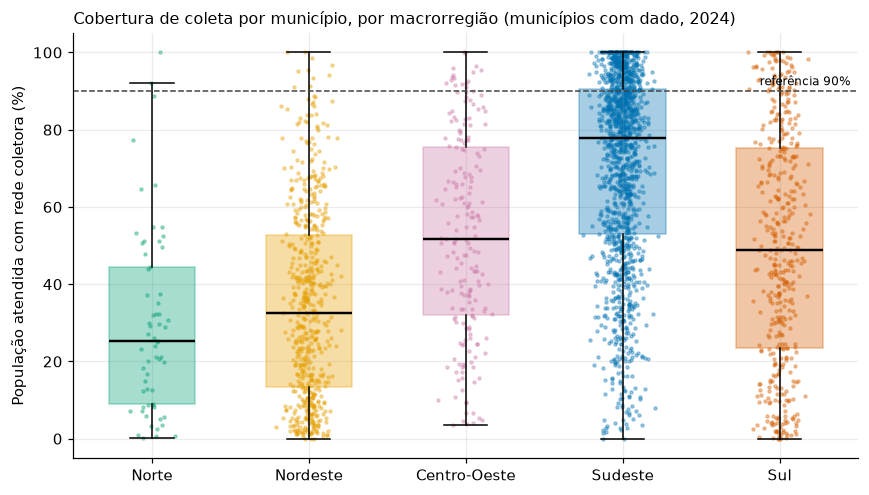

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.6))
bp = ax.boxplot(grupos, tick_labels=ORDEM, showfliers=False, patch_artist=True, widths=.55, medianprops=dict(color="black", lw=1.6))
rng = np.random.default_rng(42)
for i, (m, g) in enumerate(zip(ORDEM, grupos), start=1):
    bp["boxes"][i - 1].set(facecolor=CORES[m], alpha=.35, edgecolor=CORES[m])
    ax.scatter(rng.normal(i, .07, len(g)), g, s=4, color=CORES[m], alpha=.35)
ax.axhline(90, ls="--", color="#444", lw=1); ax.text(5.45, 91.5, "referência 90%", ha="right", fontsize=8)
ax.set_ylabel("População atendida com rede coletora (%)")
ax.set_title("Cobertura de coleta por município, por macrorregião (municípios com dado, 2024)", loc="left", fontsize=10.5)
fig.tight_layout(); fig.savefig(ASSETS / "fig1_boxplot_macrorregiao.png"); plt.show()

In [7]:
ufr = resumo("uf").sort_values("cobertura")
R["uf_top"] = ufr.tail(3).iloc[::-1].round(1)[["cobertura"]].reset_index().to_dict("records")
R["uf_bottom"] = ufr.head(3).round(1)[["cobertura"]].reset_index().to_dict("records")
R["uf_acima_90"] = ufr[ufr.cobertura >= 90].index.tolist()
fig = go.Figure()
fig.add_bar(y=ufr.index, x=ufr.cobertura.round(1), orientation="h", name="Rede coletora", marker_color="#0072B2",
            customdata=np.c_[ufr.n, ufr.n_com_dado, ufr.pop_mi.round(2)],
            hovertemplate="<b>%{y}</b><br>Rede coletora: %{x}%<br>Municípios: %{customdata[0]} (%{customdata[1]} com dado)<br>Pop.: %{customdata[2]} mi<extra></extra>")
fig.add_bar(y=ufr.index, x=ufr.efetiva.round(1), orientation="h", name="Coleta e tratamento (estimativa)", marker_color="#E69F00",
            hovertemplate="<b>%{y}</b><br>Coleta + tratamento: %{x}%<extra></extra>")
fig.add_vline(x=90, line_dash="dash", line_color="#444", annotation_text="90%")
fig.update_layout(barmode="group", height=780, template="plotly_white", margin=dict(l=40, r=20, t=60, b=40),
                  title="Atendimento por UF (% da população; município sem dado conta como não atendido)",
                  xaxis_title="% da população", legend=dict(orientation="h", y=1.04, x=0))
fig.write_html(ASSETS / "fig2_uf_interativo.html", include_plotlyjs="cdn"); fig.show()

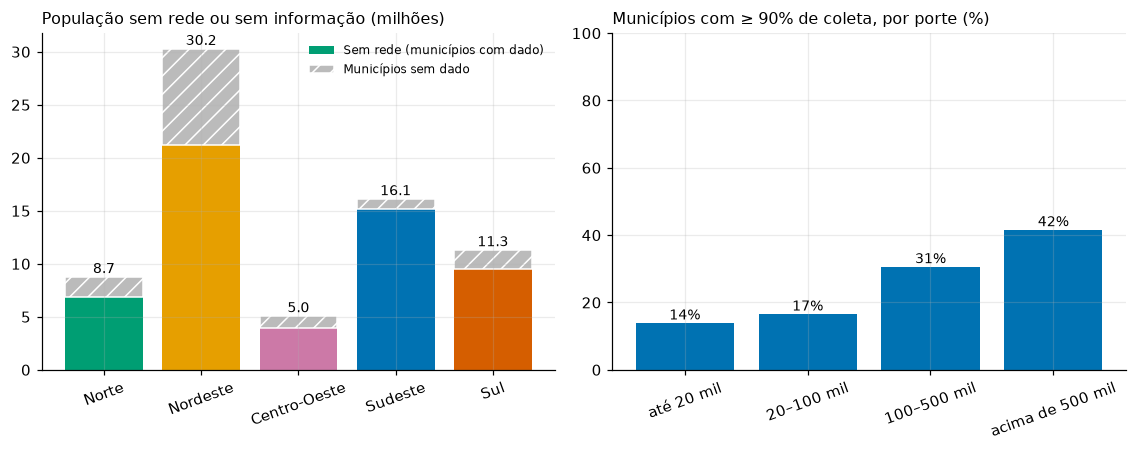

In [8]:
faixa = resumo("faixa_pop")
R["faixa"] = faixa.round(2).reset_index().to_dict("records")
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.2))
b1 = ax[0].bar(macro.index, macro.sem_rede_mi, color=[CORES[m] for m in macro.index], label="Sem rede (municípios com dado)")
ax[0].bar(macro.index, macro.sem_dado_mi, bottom=macro.sem_rede_mi, color="#bbb", hatch="//", edgecolor="white", label="Municípios sem dado")
for i, (a, b) in enumerate(zip(macro.sem_rede_mi, macro.sem_dado_mi)): ax[0].text(i, a + b + .4, f"{a + b:.1f}", ha="center", fontsize=9)
ax[0].set_title("População sem rede ou sem informação (milhões)", loc="left", fontsize=10.5)
ax[0].tick_params(axis="x", labelrotation=20); ax[0].legend(frameon=False, fontsize=8)
ax[1].bar(faixa.index.astype(str), faixa.pct_meta90, color="#0072B2")
for i, v in enumerate(faixa.pct_meta90): ax[1].text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
ax[1].set_title("Municípios com ≥ 90% de coleta, por porte (%)", loc="left", fontsize=10.5); ax[1].set_ylim(0, 100)
ax[1].tick_params(axis="x", labelrotation=20)
fig.tight_layout(); fig.savefig(ASSETS / "fig3_sem_rede_e_porte.png"); plt.show()

## 3. RQ2 — Natureza jurídica do prestador

In [9]:
principais = ["Sociedade de economia mista", "Empresa privada", "Município (adm. direta)", "Autarquia", "Outras ou múltiplas"]
nat = com.groupby("natureza_grupo").agg(n=("cod_ibge", "size"), pop_mediana=("pop_total", "median"),
        coleta_mediana=("atend_rede_pop_total", "median"), trat_mediana=("trat_sobre_coletado", "median"),
        extrav_mediana=("extravasamentos_por_km", "median")).loc[principais]
R["natureza"] = nat.round(2).reset_index().to_dict("records")
for var in ("atend_rede_pop_total", "trat_sobre_coletado"):
    gs = [com.loc[com.natureza_grupo == g, var].dropna() for g in principais]
    H, p = stats.kruskal(*gs); n, k = sum(map(len, gs)), len(gs)
    R[f"kw_nat_{var}"] = {"H": H, "p": p, "eps2": (H - k + 1) / (n - k)}
# controle simples: mesma comparação só no Sudeste (região mais heterogênea em prestadores)
se = com[com.macrorregiao == "Sudeste"]; gs = [se.loc[se.natureza_grupo == g, "atend_rede_pop_total"].dropna() for g in principais[:4]]
H, p = stats.kruskal(*gs); R["kw_nat_sudeste"] = {"H": H, "p": p}
print({k: v for k, v in R.items() if k.startswith("kw_nat")}); nat.round(1)

{'kw_nat_atend_rede_pop_total': {'H': np.float64(366.84071702918806), 'p': np.float64(4.0491073445108156e-78), 'eps2': np.float64(0.13325035513374514)}, 'kw_nat_trat_sobre_coletado': {'H': np.float64(844.6091071915422), 'p': np.float64(1.667691176801811e-181), 'eps2': np.float64(0.3087069802392737)}, 'kw_nat_sudeste': {'H': np.float64(245.76642153025918), 'p': np.float64(5.388370160633613e-53)}}


,n,pop_mediana,coleta_mediana,trat_mediana,extrav_mediana
natureza_grupo,,,,,
Sociedade de economia mista,978,21874.0,43.2,100.0,1.5
Empresa privada,597,18836.0,76.1,100.0,0.2
Município (adm. direta),587,7452.0,75.6,0.0,0.9
Autarquia,316,35141.5,80.1,95.0,1.8
Outras ou múltiplas,271,14173.0,47.5,0.0,2.9


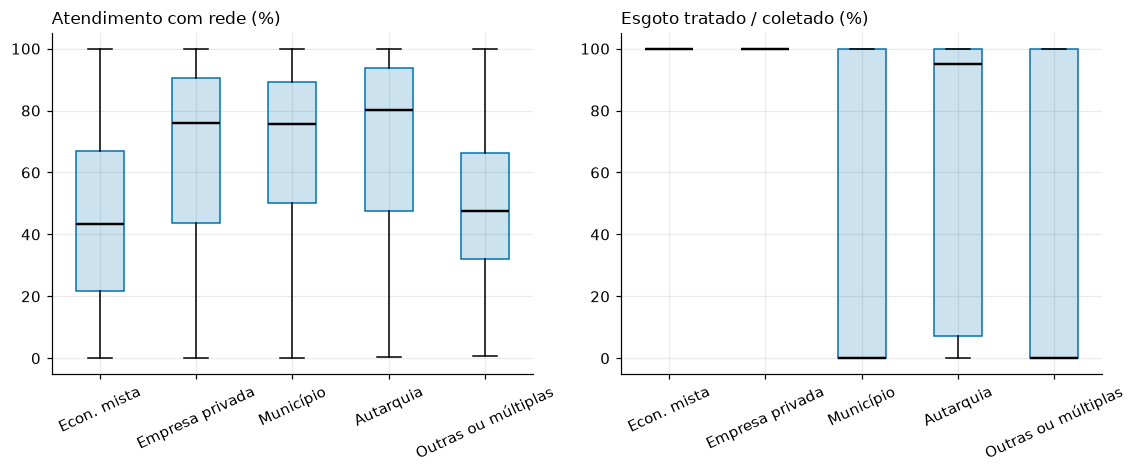

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.4), sharey=False)
for a, var, tit in zip(ax, ["atend_rede_pop_total", "trat_sobre_coletado"],
                       ["Atendimento com rede (%)", "Esgoto tratado / coletado (%)"]):
    dados = [com.loc[com.natureza_grupo == g, var].dropna().clip(upper=100) for g in principais]
    a.boxplot(dados, tick_labels=[g.replace(" (adm. direta)", "").replace("Sociedade de economia mista", "Econ. mista")
                                  for g in principais], showfliers=False, patch_artist=True,
              boxprops=dict(facecolor="#0072B233", edgecolor="#0072B2"), medianprops=dict(color="black", lw=1.6))
    a.set_title(tit, loc="left", fontsize=11); a.tick_params(axis="x", labelrotation=25)
fig.tight_layout(); fig.savefig(ASSETS / "fig4_natureza_juridica.png"); plt.show()

In [11]:
med = com.pivot_table(index="natureza_grupo", columns="macrorregiao", values="atend_rede_pop_total", aggfunc="median").loc[principais, ORDEM]
cnt = com.pivot_table(index="natureza_grupo", columns="macrorregiao", values="cod_ibge", aggfunc="size").loc[principais, ORDEM]
fig = go.Figure(go.Heatmap(z=med.values.round(1), x=ORDEM, y=principais, colorscale="Blues", zmin=0, zmax=100,
                           text=[[f"{v:.0f}%<br>n={int(c) if c == c else 0}" for v, c in zip(r, rc)] for r, rc in zip(med.values, cnt.values)],
                           texttemplate="%{text}", colorbar=dict(title="Mediana (%)"),
                           hovertemplate="%{y} · %{x}<br>Mediana: %{z}%<extra></extra>"))
fig.update_layout(template="plotly_white", height=420, title="Mediana de atendimento com rede: natureza jurídica × macrorregião",
                  margin=dict(l=40, r=20, t=60, b=40), yaxis_autorange="reversed")
fig.write_html(ASSETS / "fig5_natureza_x_macro.html", include_plotlyjs="cdn"); fig.show()

## 4. RQ3 — Desempenho financeiro × cobertura e tratamento

In [12]:
d3 = com.copy(); d3["log10_pop"] = np.log10(d3.pop_total)
cols = ["atend_rede_pop_total", "trat_sobre_coletado", "desempenho_financeiro_pct", "receita_direta_rs_m3",
        "despesa_total_rs_m3", "evasao_receita_pct", "energia_kwh_m3", "log10_pop"]
rot = ["Coleta (%)", "Trat./coletado (%)", "Desemp. financeiro (%)", "Receita (R$/m³)", "Despesa (R$/m³)", "Evasão (%)", "Energia (kWh/m³)", "log10 pop."]
corr = d3[cols].corr(method="spearman")
R["spearman"] = corr.round(3).to_dict()
R["n_par_desemp_coleta"] = int(d3[["atend_rede_pop_total", "desempenho_financeiro_pct"]].dropna().shape[0])
# quartis de desempenho financeiro (por postos, imune a outliers)
d3["q_desemp"] = pd.qcut(d3.desempenho_financeiro_pct, 4, labels=["Q1 (menor)", "Q2", "Q3", "Q4 (maior)"])
quart = d3.groupby("q_desemp", observed=True).agg(n=("cod_ibge", "size"), coleta=("atend_rede_pop_total", "median"),
                                                  sem_trat=("trat_sobre_coletado", lambda v: (v.dropna() == 0).mean() * 100), limite_max=("desempenho_financeiro_pct", "max"))
R["quartis"] = quart.round(2).reset_index().astype({"q_desemp": str}).to_dict("records")
quart.round(1)

,n,coleta,sem_trat,limite_max
q_desemp,,,,
Q1 (menor),685,55.6,60.7,32.1
Q2,685,44.0,6.5,88.4
Q3,685,71.7,6.4,121.2
Q4 (maior),685,75.2,12.2,1942.4


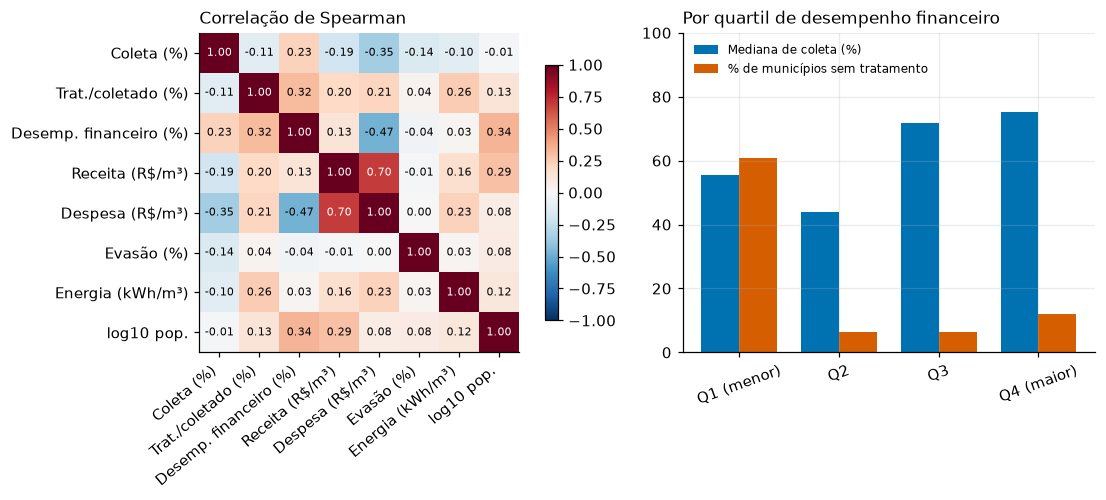

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
im = ax[0].imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(rot)), rot, rotation=40, ha="right"); ax[0].set_yticks(range(len(rot)), rot); ax[0].grid(False)
for i in range(len(rot)):
    for j in range(len(rot)): ax[0].text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(corr.values[i, j]) > .6 else "black")
ax[0].set_title("Correlação de Spearman", loc="left", fontsize=11); fig.colorbar(im, ax=ax[0], shrink=.8)
x = np.arange(4); w = .38
ax[1].bar(x - w / 2, quart.coleta, w, label="Mediana de coleta (%)", color="#0072B2"); ax[1].bar(x + w / 2, quart.sem_trat, w, label="% de municípios sem tratamento", color="#D55E00")
ax[1].set_xticks(x, quart.index, rotation=20); ax[1].set_ylim(0, 100); ax[1].legend(frameon=False, loc="upper left", fontsize=8)
ax[1].set_title("Por quartil de desempenho financeiro", loc="left", fontsize=11)
fig.tight_layout(); fig.savefig(ASSETS / "fig6_financeiro.png"); plt.show()

In [14]:
s = d3[["municipio", "uf", "macrorregiao", "pop_total", "atend_rede_pop_total", "receita_direta_rs_m3"]].dropna()
lo, hi = s.receita_direta_rs_m3.quantile([.01, .99]); s = s[s.receita_direta_rs_m3.between(max(lo, .01), hi)]
R["scatter_n"] = len(s); R["scatter_faixa"] = [float(lo), float(hi)]
fig = px.scatter(s, x="receita_direta_rs_m3", y="atend_rede_pop_total", color="macrorregiao", size="pop_total", size_max=28,
                 log_x=True, color_discrete_map=CORES, category_orders={"macrorregiao": ORDEM}, opacity=.6,
                 hover_name="municipio", hover_data={"uf": True, "pop_total": ":,.0f", "receita_direta_rs_m3": ":.2f", "atend_rede_pop_total": ":.1f"},
                 labels={"receita_direta_rs_m3": "Receita operacional direta média (R$/m³, escala log)",
                         "atend_rede_pop_total": "Atendimento com rede (%)", "macrorregiao": "Macrorregião"})
fig.update_layout(template="plotly_white", height=520, margin=dict(l=40, r=20, t=50, b=40),
                  title="Receita por m³ × cobertura (tamanho = população; percentis 1–99 da receita)")
fig.write_html(ASSETS / "fig7_receita_cobertura.html", include_plotlyjs="cdn"); fig.show()

## 5. Exportar números do artigo

In [15]:
(ASSETS / "resultados.json").write_text(json.dumps(R, ensure_ascii=False, indent=1, default=float), encoding="utf-8")
print(sorted(p.name for p in ASSETS.iterdir()))

['fig1_boxplot_macrorregiao.png', 'fig2_uf_interativo.html', 'fig3_sem_rede_e_porte.png', 'fig4_natureza_juridica.png', 'fig5_natureza_x_macro.html', 'fig6_financeiro.png', 'fig7_receita_cobertura.html', 'resultados.json']
